In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from pathlib import Path
import shutil
import kagglehub 

In [3]:
import kagglehub
import shutil
from pathlib import Path


PROJECT_ROOT = Path.cwd().parent
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)

print("بدء تحميل بيانات Olist...")


dataset_path = kagglehub.dataset_download(
    "olistbr/brazilian-ecommerce"
)

source_dir = Path(dataset_path)
print(f"تم تنزيل الداتا في مسار الكاش: {source_dir}")


csv_files = list(source_dir.glob("*.csv"))

for file in csv_files:
    destination = RAW_DATA_DIR / file.name
    shutil.copy2(file, destination)
    print(f"تم نسخ الملف: {file.name}")

print("تم الانتهاء من جمع وتنزيل جميع الملفات بنجاح!")

بدء تحميل بيانات Olist...
تم تنزيل الداتا في مسار الكاش: C:\Users\dell\.cache\kagglehub\datasets\olistbr\brazilian-ecommerce\versions\2
تم نسخ الملف: olist_customers_dataset.csv
تم نسخ الملف: olist_geolocation_dataset.csv
تم نسخ الملف: olist_orders_dataset.csv
تم نسخ الملف: olist_order_items_dataset.csv
تم نسخ الملف: olist_order_payments_dataset.csv
تم نسخ الملف: olist_order_reviews_dataset.csv
تم نسخ الملف: olist_products_dataset.csv
تم نسخ الملف: olist_sellers_dataset.csv
تم نسخ الملف: product_category_name_translation.csv
تم الانتهاء من جمع وتنزيل جميع الملفات بنجاح!


In [4]:
import pandas as pd

df_products = pd.read_csv("../data/raw/olist_products_dataset.csv")

# check size
print("Products Shape (Rows, Columns):", df_products.shape)

# display 3 row for check
df_products.head(3)

Products Shape (Rows, Columns): (32951, 9)


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0


In [5]:
#check missing value and clean data
missing_values = df_products.isnull().sum()
print(missing_values[missing_values > 0])

product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64


In [6]:

print("Total rows before cleaning:", len(df_products))


df_products_cleaned = df_products.dropna(subset=['product_weight_g'])

print("Total rows after cleaning dimensions:", len(df_products_cleaned))

Total rows before cleaning: 32951
Total rows after cleaning dimensions: 32949


In [7]:
# explain type (شكل البيانات) data
df_products_cleaned.describe()

,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,32340.000000,32340.000000,32340.000000,32949.000000,32949.000000,32949.000000,32949.000000
mean,48.476592,771.492393,2.188961,2276.472488,30.815078,16.937661,23.196728
std,10.245699,635.124831,1.736787,4282.038731,16.914458,13.637554,12.079047
min,5.000000,4.000000,1.000000,0.000000,7.000000,2.000000,6.000000
25%,42.000000,339.000000,1.000000,300.000000,18.000000,8.000000,15.000000
50%,51.000000,595.000000,1.000000,700.000000,25.000000,13.000000,20.000000
75%,57.000000,972.000000,3.000000,1900.000000,38.000000,21.000000,30.000000
max,76.000000,3992.000000,20.000000,40425.000000,105.000000,105.000000,118.000000


In [8]:
# معرفة الأعمدة المتاحة في المنتجات للتحليل
print("Products Columns:", df_products_cleaned.columns.tolist())


Products Columns: ['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']


In [9]:
# قراءة جدول عناصر الطلبات لربطه بالمنتجات
df_order_items = pd.read_csv("../data/raw/olist_order_items_dataset.csv")

print("Order Items Shape:", df_order_items.shape)

# دمج جدول المنتجات مع عناصر (order)
df_merged = pd.merge(df_order_items, df_products_cleaned, on='product_id', how='inner')
print("Merged Shape (Order Items + Products):", df_merged.shape)

# Display best (اكثر مبيعا)
print("\nTop 5 Product Categories by Sales Count:")
print(df_merged['product_category_name'].value_counts().head(5))

Order Items Shape: (112650, 7)
Merged Shape (Order Items + Products): (112632, 15)

Top 5 Product Categories by Sales Count:
product_category_name
cama_mesa_banho           11115
beleza_saude               9670
esporte_lazer              8641
moveis_decoracao           8334
informatica_acessorios     7827
Name: count, dtype: int64



Price Statistics:


count    112632.000000
mean        120.650851
std         183.565939
min           0.850000
25%          39.900000
50%          74.990000
75%         134.900000
max        6735.000000
Name: price, dtype: float64

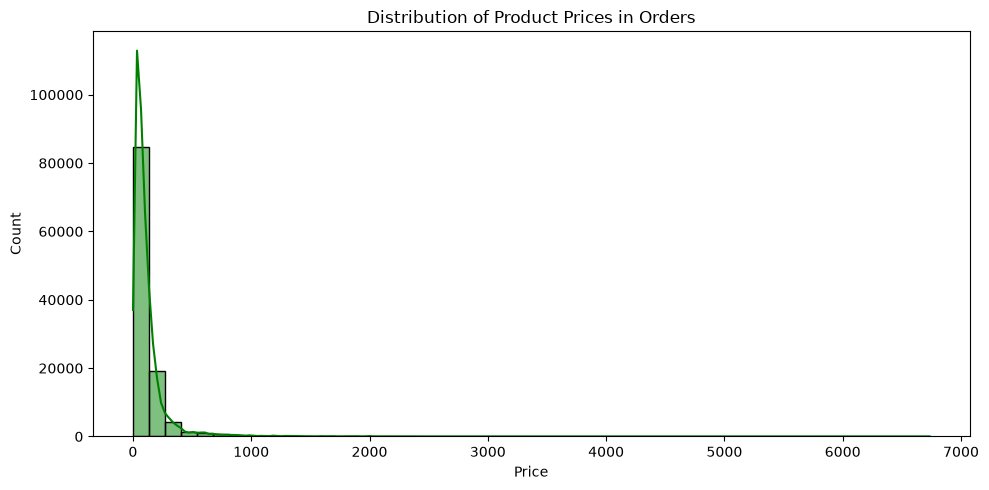

In [12]:
# ==============================
# 11. Price Analysis and Outliers
# ==============================

print("\nPrice Statistics:")
display(df_merged["price"].describe())

# رسم توضيحي لتوزيع الأسعار
plt.figure(figsize=(10, 5))
sns.histplot(df_merged["price"], bins=50, kde=True, color="green")
plt.title("Distribution of Product Prices in Orders")
plt.xlabel("Price")
plt.ylabel("Count")
plt.tight_layout()
plt.show()